## Setup

We run this notebook on Google Colab. The first cell installs Qiskit (`pylatexenc` is only needed by Qiskit to draw circuits with matplotlib).

The second cell contains the imports and the circle-notation code given in *1.1.1 - Python Code for Circle Notation*, which we use in all the tasks. We made only one small change: the phase arrow is drawn only when the probability of the state is not zero. A state with zero amplitude has no meaningful phase, and without this check tiny numerical errors (of order $10^{-16}$) would draw random-looking arrows.

> **Conventions.**
> - Qiskit orders the qubits *little-endian*: qubit 0 is the least significant bit. A 3-qubit basis state is written $|q_2 q_1 q_0\rangle$, so for example $|4\rangle = |100\rangle$.
> - In the circle plots the phase is measured from the positive x-axis (arrow pointing right = phase 0, counter-clockwise = positive angles). The book and the lecture slides measure it from the positive y-axis instead.

In [1]:
%pip install -q qiskit pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 82.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 80.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.2 MB/s eta 0:00:00


In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, QuantumRegister
from qiskit.quantum_info import Statevector


def sv_from_circ(circ: QuantumCircuit) -> np.ndarray:
    """Simulate the circuit and return its state vector as a numpy array."""
    sv = Statevector(circ)
    return np.asarray(sv, dtype=np.complex128)


class QubitSystem:
    def __init__(self, statevector: np.ndarray, label: str = "Qubit System"):
        self.label = label
        self.set_statevector(statevector)

    def set_statevector(self, statevector: np.ndarray):
        sv = np.asarray(statevector, dtype=np.complex128).flatten()
        if sv.ndim != 1:
            raise ValueError("Statevector must be 1D.")
        n_states = sv.size
        n_qubits = int(round(math.log2(n_states)))
        if 2**n_qubits != n_states:
            raise ValueError("Length must be a power of 2.")
        # Defensive normalization (harmless if already normalized)
        norm = np.linalg.norm(sv)
        if norm != 0 and not np.isclose(norm, 1.0):
            sv = sv / norm

        self.n_qubits = n_qubits
        self.n_states = n_states
        self.amps  = sv
        self.prob  = np.abs(sv)**2
        self.phase = np.angle(sv)

    def viz_circle(self, max_cols: int = 8, figsize_scale: float = 2.3):
        cols = max(1, min(max_cols, self.n_states))
        rows = int(math.ceil(self.n_states / cols))

        fig, axes = plt.subplots(
            rows, cols,
            figsize=(cols*figsize_scale, rows*(figsize_scale+0.2))
        )
        axes = np.atleast_2d(axes)

        def bitstr(i: int, n: int) -> str:
            return format(i, f"0{n}b")

        for idx in range(rows * cols):
            r, c = divmod(idx, cols)
            ax = axes[r, c]
            ax.set_aspect("equal")
            ax.set_xlim(0, 1); ax.set_ylim(0, 1)
            ax.axis("off")

            if idx >= self.n_states:
                ax.set_visible(False)
                continue

            # Outer reference circle
            ax.add_patch(plt.Circle((0.5, 0.5), 0.48, fill=False, lw=1.0, alpha=0.5))

            # Filled disk: radius ∝ sqrt(probability) so area ∝ probability
            radius = 0.48 * np.sqrt(self.prob[idx])
            ax.add_patch(plt.Circle((0.5, 0.5), radius, alpha=0.25))

            # Phase arrow (our change: only for non-zero amplitudes, the phase of 0 has no meaning)
            if self.prob[idx] > 1e-10:
                angle = self.phase[idx]
                L = 0.45
                x2 = 0.5 + L * np.cos(angle)
                y2 = 0.5 + L * np.sin(angle)
                ax.arrow(0.5, 0.5, x2 - 0.5, y2 - 0.5,
                         head_width=0.03, head_length=0.05, length_includes_head=True)

            ax.set_title(f"|{bitstr(idx, self.n_qubits)}⟩", fontsize=10)

        fig.suptitle(self.label, fontsize=12)
        plt.tight_layout()
        plt.show()


def circle_plot(circ: QuantumCircuit, label: str):
    """Shortcut: simulate the circuit and show its state in circle notation."""
    QubitSystem(sv_from_circ(circ), label=label).viz_circle()

# Task 1 - Quantum Arithmetics

Implement 3-qubit increment and decrement operators using IBM Qiskit, then inspect the states using circle notation.

## Task 1.1 - Increment and Decrement Operator

1. Prepare a superposition of quantum states using HAD QPU instructions. You can decide freely which superposition. This will determine the concurrent increment or decrement operator.
2. Plot the quantum states using the circle notation.
IBM Qiskit does not support visualization for this step; you will need to implement a Python routine to visualize the quantum states of our qubit. You can find a Python code to perform this task at 1.1.1 - Python Code for Circle Notation.
3. Perform an increment operation (by 1) +=
4. Plot the quantum states using the circular notation
5. Perform a decrement operation (by 1) -=
6. Plot the quantum states using the circular notation

> What to include. The chosen initial superposition, both circuits, and all three circle-notation plots.

### Our Solution

**Chosen initial superposition.** We start from $|000\rangle$ and apply a Hadamard gate to $q_0$ and to $q_2$. Each Hadamard puts its qubit in $(|0\rangle + |1\rangle)/\sqrt{2}$, so the register becomes an equal superposition of four values:

$$|\psi_0\rangle = \tfrac{1}{2}\big(|0\rangle + |1\rangle + |4\rangle + |5\rangle\big) = \tfrac{1}{2}\big(|000\rangle + |001\rangle + |100\rangle + |101\rangle\big)$$

**Increment circuit (+1).** When we add 1 to a binary number, the lowest bit always flips, and a higher bit flips only if *all the bits below it are 1* (this is the carry). As in the lectures, we build this with reversible gates, going from the most significant bit down:

1. `CCX(q0, q1 → q2)`: flip $q_2$ if $q_0 = q_1 = 1$
2. `CX(q0 → q1)`: flip $q_1$ if $q_0 = 1$
3. `X(q0)`: always flip $q_0$


**Decrement circuit (−1).** Decrementing is the inverse of incrementing. The gates X, CX and CCX are their own inverse, so the inverse circuit is simply the same gates in the reverse order: `X(q0)`, `CX(q0 → q1)`, `CCX(q0, q1 → q2)`.

Since the gates are linear, the circuit acts on every value of the superposition at the same time: this is the "concurrent" increment and decrement mentioned in the task.

Increment:


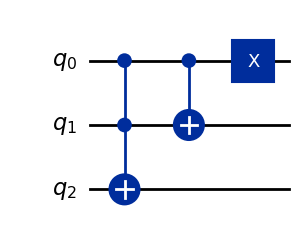

Decrement:


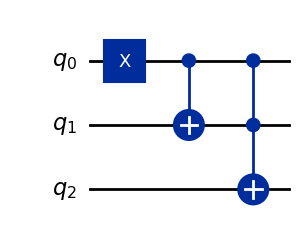

In [3]:
def increment(qc, q):
    """Add 1 (mod 8) to the 3-qubit register q = [q0, q1, q2], q0 = least significant bit."""
    qc.ccx(q[0], q[1], q[2])  # carry into q2: flip it if q0 = q1 = 1
    qc.cx(q[0], q[1])         # carry into q1: flip it if q0 = 1
    qc.x(q[0])                # always flip q0


def decrement(qc, q):
    """Subtract 1 (mod 8): the increment gates in reverse order."""
    qc.x(q[0])
    qc.cx(q[0], q[1])
    qc.ccx(q[0], q[1], q[2])


q = [0, 1, 2]

# Increment circuit
inc_circuit = QuantumCircuit(3)
increment(inc_circuit, q)

# Decrement circuit
dec_circuit = QuantumCircuit(3)
decrement(dec_circuit, q)

print("Increment:")
display(inc_circuit.draw("mpl"))
print("Decrement:")
display(dec_circuit.draw("mpl"))

**Running the three steps.** We now build one circuit that prepares $|\psi_0\rangle$, increments it and then decrements it, and we plot the state after each step.

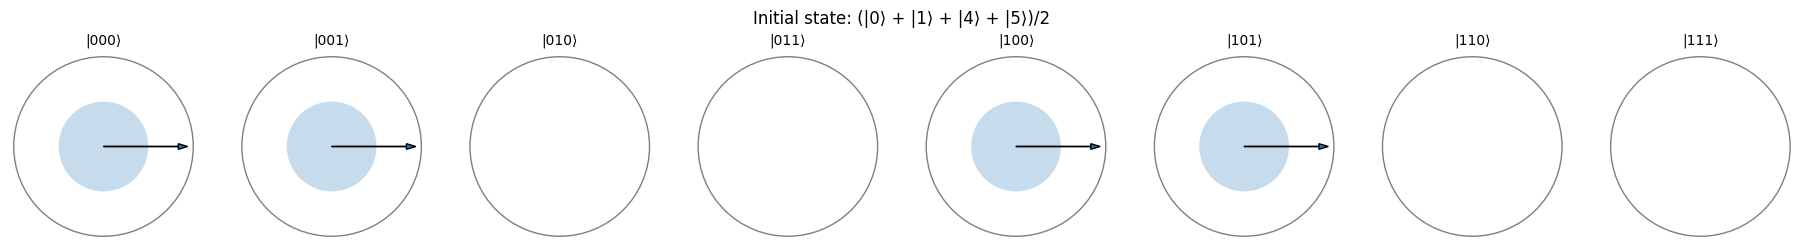

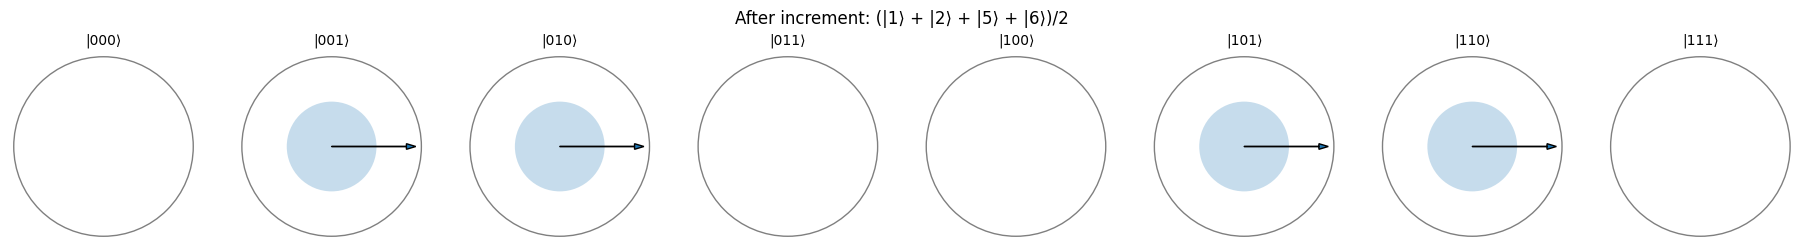

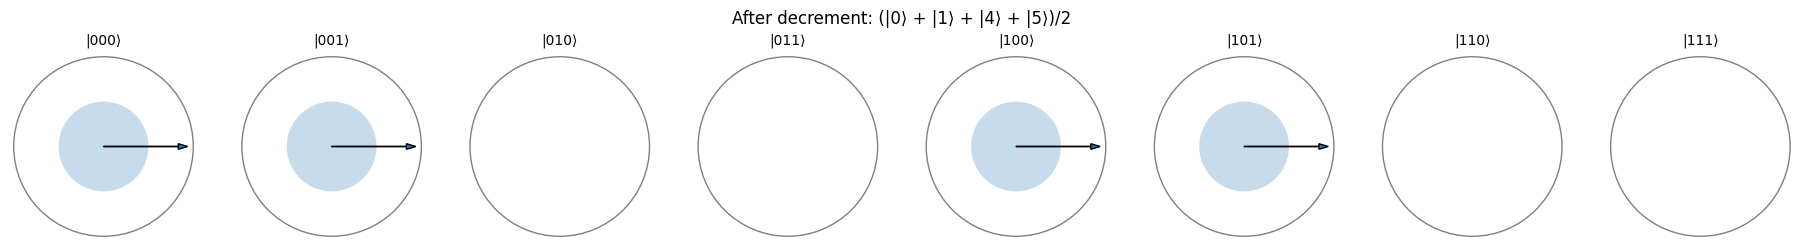

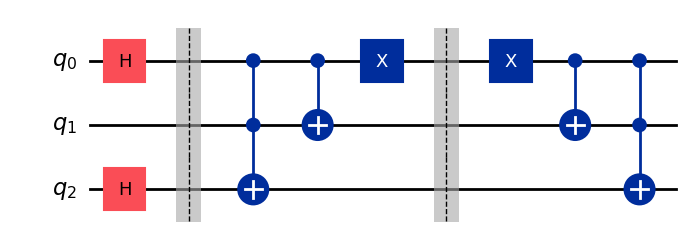

In [4]:
qc = QuantumCircuit(3)

# Initial superposition with Hadamard gates
qc.h(0)
qc.h(2)
circle_plot(qc, "Initial state: (|0⟩ + |1⟩ + |4⟩ + |5⟩)/2")

# Increment by 1
qc.barrier()
increment(qc, q)
circle_plot(qc, "After increment: (|1⟩ + |2⟩ + |5⟩ + |6⟩)/2")

# Decrement by 1
qc.barrier()
decrement(qc, q)
circle_plot(qc, "After decrement: (|0⟩ + |1⟩ + |4⟩ + |5⟩)/2")

# Circuit
qc.draw("mpl")

**What the plots show.**
- *Initial state:* four circles are filled equally ($|000\rangle, |001\rangle, |100\rangle, |101\rangle$), each with probability $1/4$ and phase 0 (all arrows point right).
- *After the increment:* the same four filled circles moved one place forward: $0\to1$, $1\to2$, $4\to5$, $5\to6$. The size and the phase of every circle did not change. The increment only *moves* the amplitudes between basis states (it is a permutation of the basis states), it does not create or destroy anything.
- *After the decrement:* we are back exactly to the initial state. This confirms that the decrement is the inverse of the increment.


> **Note on the phase convention:** Similar to the previous assignment, the circle notation adopted here represents a relative phase of $0$ with arrows pointing to the right (positive x-axis). This differs from the convention used in the lectures, where a phase of zero is represented by an arrow pointing upwards (positive y-axis).


## Task 1.2 - Overflow, Underflow, and Negative Numbers

1. What happens on overflow during increment or underflow during decrement? Show both with an experiment.
2. Do increment and decrement also work with negative integers? Motivate the answer with an example.

> What to include. Overflow and underflow experiments, plus one explained negative-number example.

### Our Solution

#### Overflow and underflow

With 3 qubits we can only store the values $0$ to $7$. We test the two edge cases:

- **Overflow:** start from $|7\rangle = |111\rangle$ and increment.
- **Underflow:** start from $|0\rangle = |000\rangle$ and decrement.

To prepare a single number we apply an X gate on every qubit whose bit is 1.

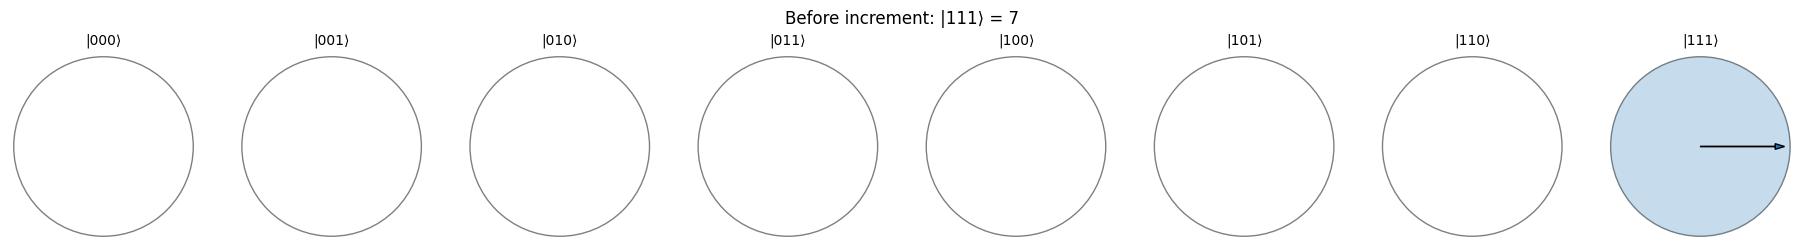

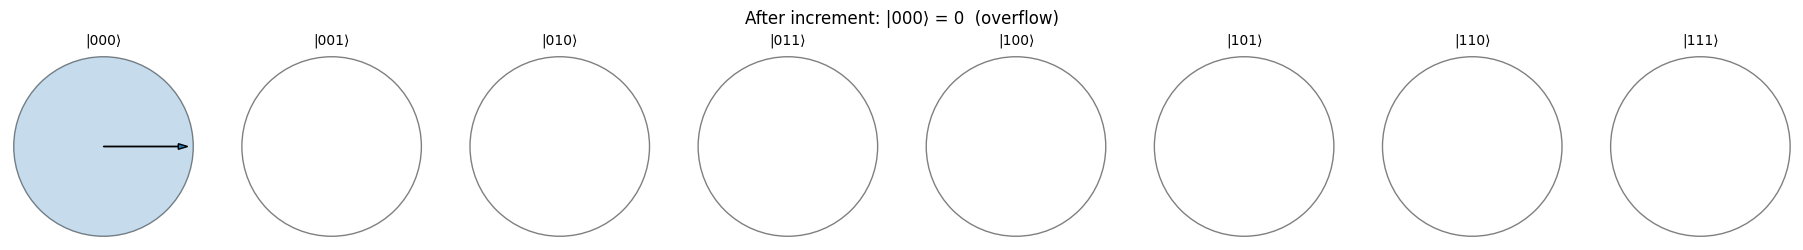

7 + 1 -> 0


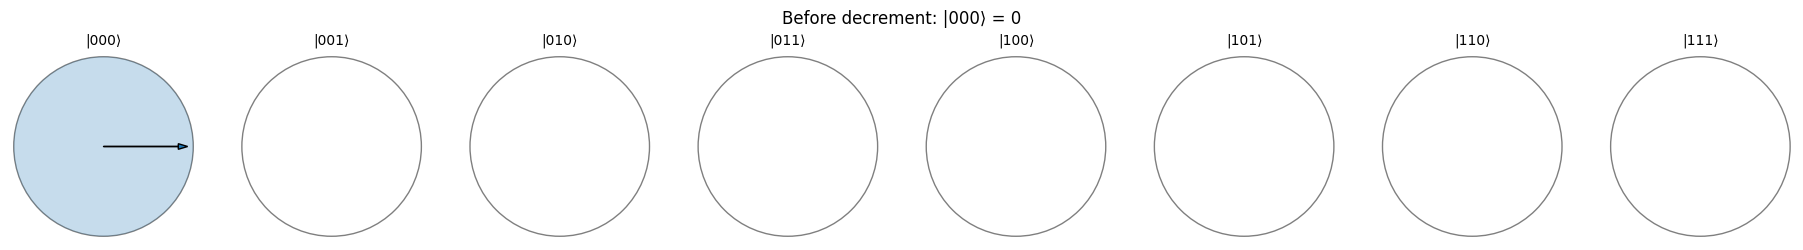

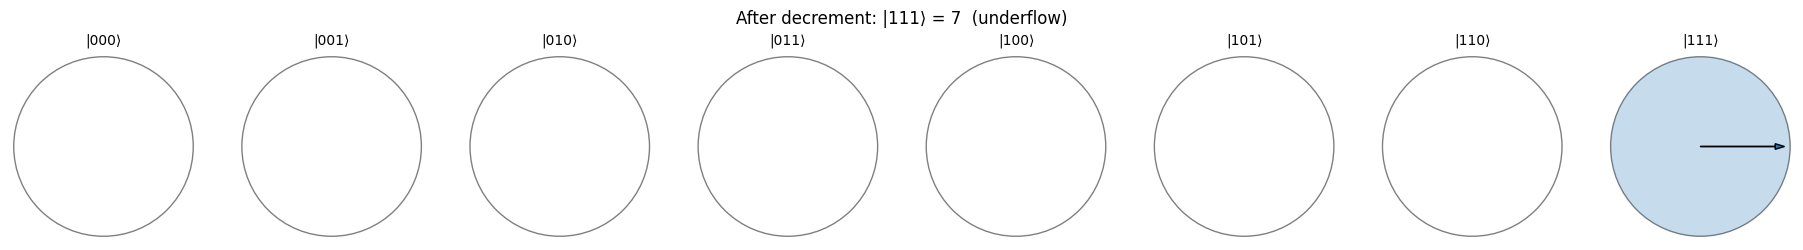

0 - 1 -> 7


In [5]:
def basis_state(value):
    """Circuit that prepares the 3-qubit basis state |value> (q0 = least significant bit)."""
    qc = QuantumCircuit(3)
    for i in range(3):
        if (value >> i) & 1:
            qc.x(i)
    return qc


def read_value(qc):
    """For a circuit whose final state is a single basis state, return its integer value."""
    return int(np.argmax(np.abs(sv_from_circ(qc))))


# Overflow: 7 + 1
qc = basis_state(7)
circle_plot(qc, "Before increment: |111⟩ = 7")
increment(qc, q)
circle_plot(qc, "After increment: |000⟩ = 0  (overflow)")
print("7 + 1 ->", read_value(qc))

# Underflow: 0 - 1
qc = basis_state(0)
circle_plot(qc, "Before decrement: |000⟩ = 0")
decrement(qc, q)
circle_plot(qc, "After decrement: |111⟩ = 7  (underflow)")
print("0 - 1 ->", read_value(qc))

**Result.** On overflow the register *wraps around*: $7 + 1$ gives $0$. All three bits are 1, so every carry fires and all the bits flip to 0. The carry that should go into a 4th bit is simply lost, because there is no 4th qubit. In the same way, on underflow $0 - 1$ gives $7$. So our circuits do arithmetic **modulo 8**.

Note that nothing "breaks": the circuit is reversible, so it cannot lose information. It just maps $7 \to 0$ instead of $7 \to 8$.

#### Negative numbers

Yes, increment and decrement also work with negative numbers, if we use the **two's complement** representation (the same one used by classical computers). With 3 bits it reads the values like this:

| bits | 000 | 001 | 010 | 011 | 100 | 101 | 110 | 111 |
|---|---|---|---|---|---|---|---|---|
| unsigned | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
| signed (two's complement) | 0 | 1 | 2 | 3 | −4 | −3 | −2 | −1 |

A negative number $-a$ is stored as $8 - a$, for example $-1$ is stored as $7 = |111\rangle$. Two's complement is exactly arithmetic modulo 8, and we just saw that our circuits compute modulo 8. So the circuits give the right answer also for negative numbers: they do not know about signs, the sign is only in how *we* read the bits. For example, the overflow experiment above ($|111\rangle \to |000\rangle$) is, in signed reading, simply $-1 + 1 = 0$.

**Example.** We prepare a superposition of $+2$ and $-2$:

$$\tfrac{1}{\sqrt 2}\big(|010\rangle + |110\rangle\big) = \tfrac{1}{\sqrt 2}\big(|{+2}\rangle + |{-2}\rangle\big)$$

using an X on $q_1$ (value 2) and a Hadamard on $q_2$ (which adds 0 or 4; and $2 + 4 = 6$ means $-2$ in two's complement). Then we increment it and, separately, decrement it. Finally we check all 8 values in a table.

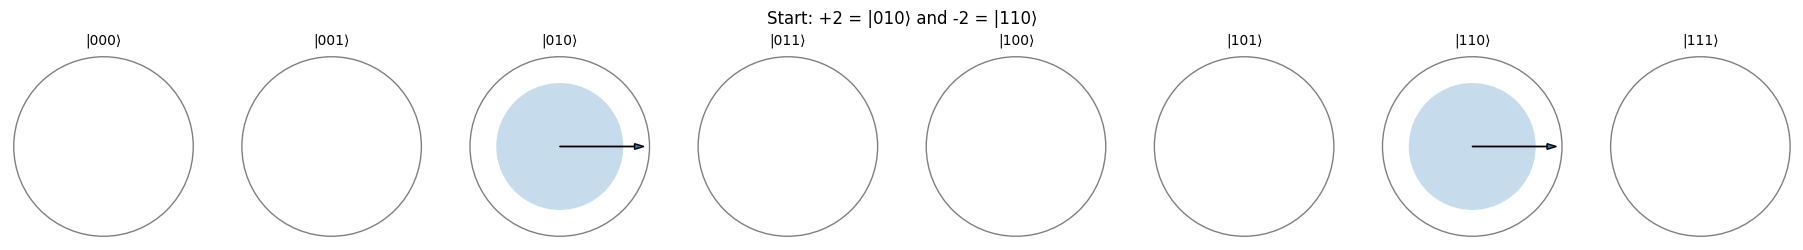

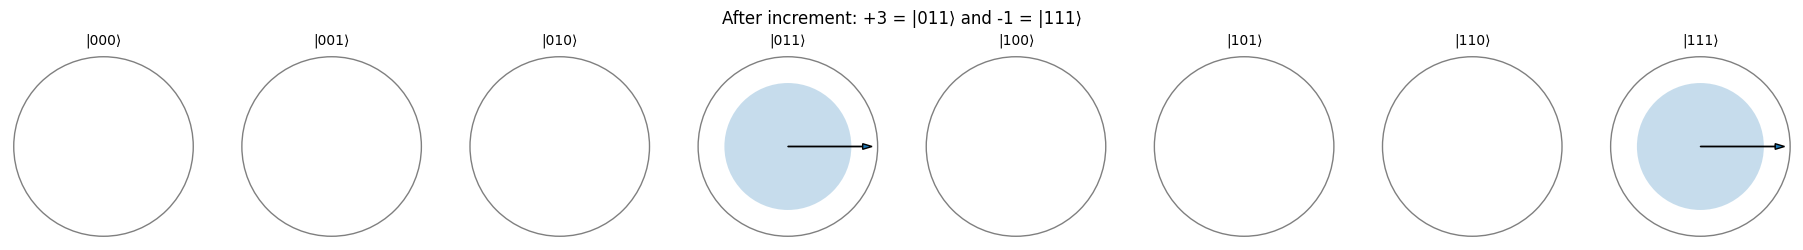

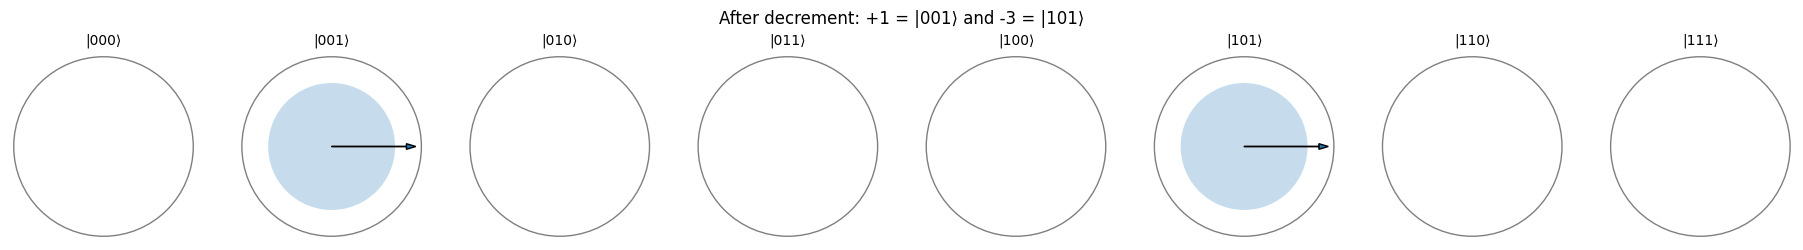

  x | x+1 | x-1
  0 |   1 |  -1
  1 |   2 |   0
  2 |   3 |   1
  3 |  -4 |   2
 -4 |  -3 |   3
 -3 |  -2 |  -4
 -2 |  -1 |  -3
 -1 |   0 |  -2


In [6]:
def to_signed(value):
    """Two's complement reading of a 3-bit value: 0..3 -> 0..3 and 4..7 -> -4..-1."""
    return value - 8 if value >= 4 else value


def plus_minus_two():
    """Superposition of +2 (|010>) and -2 (|110>)."""
    qc = QuantumCircuit(3)
    qc.x(1)  # value 2
    qc.h(2)  # add 0 or 4 -> 2 or 6, and 6 means -2 in two's complement
    return qc


qc = plus_minus_two()
circle_plot(qc, "Start: +2 = |010⟩ and -2 = |110⟩")

qc_inc = plus_minus_two()
increment(qc_inc, q)
circle_plot(qc_inc, "After increment: +3 = |011⟩ and -1 = |111⟩")

qc_dec = plus_minus_two()
decrement(qc_dec, q)
circle_plot(qc_dec, "After decrement: +1 = |001⟩ and -3 = |101⟩")

# Check all 8 values, read as signed numbers
print("  x | x+1 | x-1")
for value in range(8):
    inc = basis_state(value)
    increment(inc, q)
    dec = basis_state(value)
    decrement(dec, q)
    print(f"{to_signed(value):3d} | {to_signed(read_value(inc)):3d} | {to_signed(read_value(dec)):3d}")

**Result.** In the plots both values of the superposition are shifted correctly at the same time: $+2 \to +3$ and $-2 \to -1$ with the increment, $+2 \to +1$ and $-2 \to -3$ with the decrement.

The table confirms that $x+1$ and $x-1$ are correct for every signed value, with only two exceptions at the edges of the range $[-4, 3]$: $3 + 1$ gives $-4$, and $-4 - 1$ gives $3$. These are the signed versions of overflow and underflow: the result does not fit in 3 bits, so it wraps around exactly as before.

# Task 2 - Quantum Fourier Transform

Build a 4-qubit preparation circuit and QFT using Hadamard and controlled-phase gates, then analyze the resulting state.

The quantum Fourier transform is a crucial building block of many quantum algorithms, from Shor’s factoring algorithm to quantum phase estimation and simulations. As we saw in the lectures, QFT, like the conventional DFT and FFT, can be used to transform a function from the time domain into the frequency domain. Information about the periodic behavior of a function can be, for instance, encoded in the phases of the quantum states.

The goal of this exercise is to compute a 4-qubit QFT on a sinusoidal signal (encoded in the phase) using IBM Qiskit and plot the resulting state.  As part of this task, develop a four-qubit QFT and preparation circuit as in the circuit below.



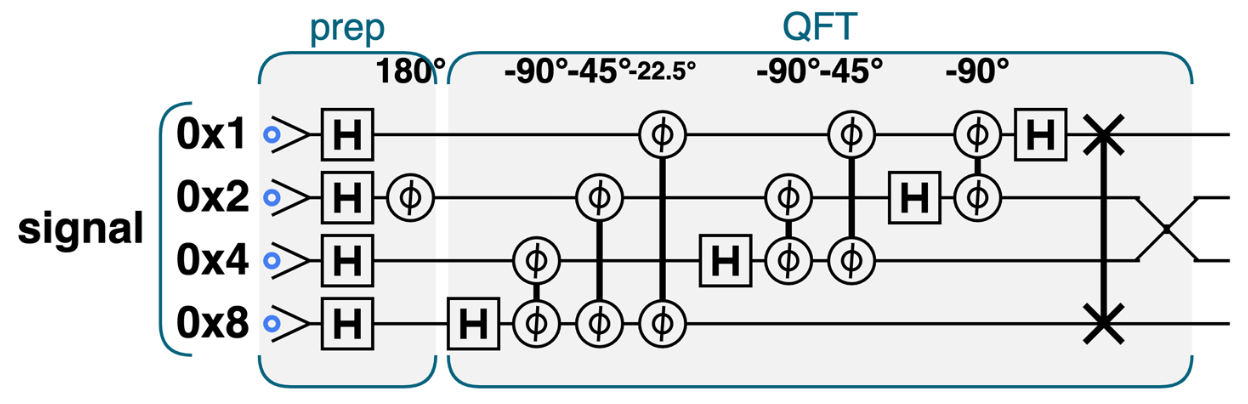

> Note that the IBM Qiskit provides a QFT function without implementing it from scratch. However, the Qiskit QFT code has a different ordering, as explained in the textbook, as pointed out in this GitHub issue: https://github.com/Qiskit/qiskit/pull/4849.

## Task 2.1 - QFT and Preparation Circuit

- Briefly describe the preparation circuit and QFT design.
- Print the complete circuit diagram.

### Our Solution

**Qubit ordering.** In the figure the qubits are labelled by the value of their bit: `0x1`, `0x2`, `0x4`, `0x8`. This matches Qiskit, where qubit 0 is the least significant bit, so `0x1` → $q_0$, `0x2` → $q_1$, `0x4` → $q_2$, `0x8` → $q_3$. The index of each basis state is then simply the number (0 to 15) stored in the register.

**Preparation circuit (the signal).**
1. A Hadamard on all 4 qubits creates the equal superposition of all 16 values: every amplitude is $1/4$ with phase 0.
2. A PHASE(180°) on $q_1$ (`0x2`) multiplies by $e^{i\pi} = -1$ every value whose `0x2` bit is 1, that is $2, 3, 6, 7, 10, 11, 14, 15$.

So all 16 values keep the same magnitude, and the information is in the phases, which follow the pattern $0°, 0°, 180°, 180°$ repeated every 4 values. This is our input signal (we analyse it in Task 2.2).

**QFT circuit.** We copy the circuit of the figure, using only Hadamard, controlled-phase (`cp`) and SWAP gates. For each qubit, from the most significant ($q_3$) down to $q_0$:
1. apply a Hadamard to it;
2. apply a controlled-phase between it and each lower qubit. The angle halves every time the two qubits are one position further apart: $-90°$, $-45°$, $-22.5°$.

At the end, two SWAPs ($q_0 \leftrightarrow q_3$ and $q_1 \leftrightarrow q_2$) reverse the order of the qubits, because the gates above produce the result with its bits in reversed order.

In total the QFT uses $4$ H + $6$ controlled-phase + $2$ SWAP $= 12$ gates. We use negative angles as in the figure: with this sign our QFT computes the same transform as the classical DFT, which we check in Task 2.3. We build the QFT ourselves instead of using Qiskit's `QFT`, which follows a different convention (see the note above).

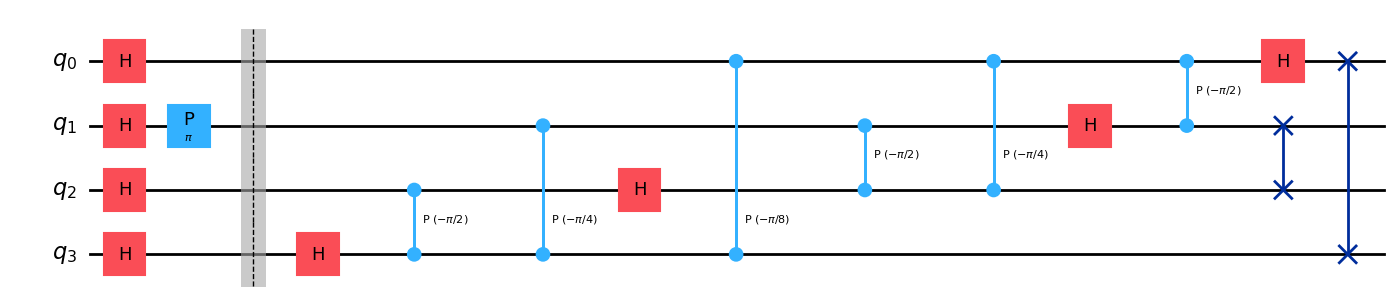

In [7]:
N_QUBITS = 4


def prepare_signal(qc):
    """Preparation part of the figure: H on every qubit, then PHASE(180°) on qubit 0x2."""
    for qubit in range(N_QUBITS):
        qc.h(qubit)
    qc.p(np.pi, 1)  # 180° on q1: flips the sign of every value with bit 0x2 = 1


def qft(qc):
    """4-qubit QFT as in the figure, built from H, controlled-phase and SWAP gates."""
    for target in reversed(range(N_QUBITS)):
        qc.h(target)
        for control in reversed(range(target)):
            angle = -np.pi / 2 ** (target - control)   # -90°, -45°, -22.5°
            qc.cp(angle, control, target)
    # Reverse order
    qc.swap(0, 3)
    qc.swap(1, 2)


full_circuit = QuantumCircuit(N_QUBITS)
prepare_signal(full_circuit)
full_circuit.barrier()  # left: preparation, right: QFT
qft(full_circuit)
full_circuit.draw("mpl")

## Task 2.2 - Circle Notation

1. Prepare the input and plot it using circle notation.
2. Identify the signal prepared by the circuit.
3. Perform the QFT and plot the resulting state using circle notation.

> What to include. Circle plots before and after the QFT, and an answer identifying the input signal.

### Our Solution

**1. Input state.** We run only the preparation circuit and plot the state in circle notation. We also print the 16 amplitudes multiplied by 4, so that we can read the signal as a list of numbers, and we plot them as a function of the basis state index $x$ (our "time" axis).

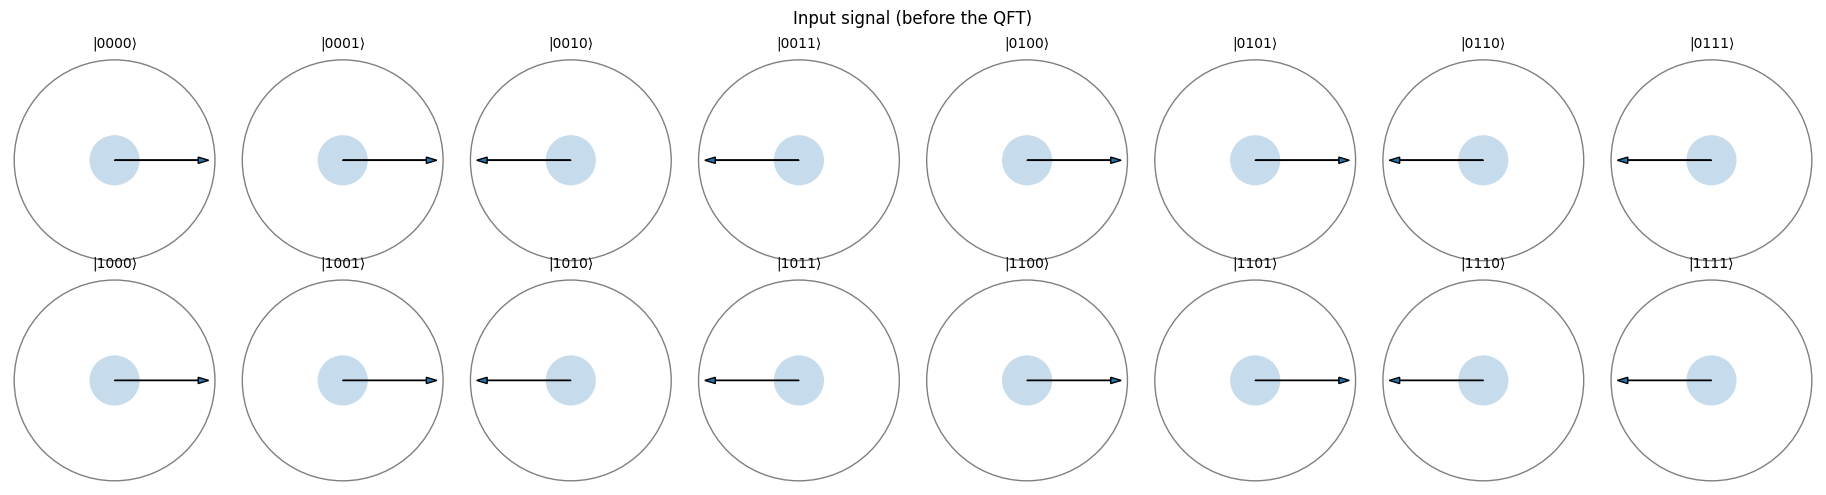

Signal (amplitudes x 4): [ 1  1 -1 -1  1  1 -1 -1  1  1 -1 -1  1  1 -1 -1]


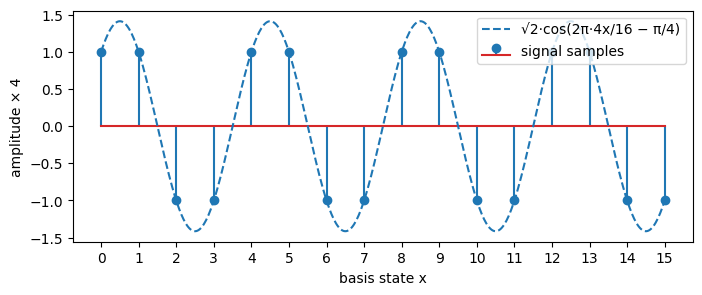

In [8]:
qc_input = QuantumCircuit(N_QUBITS)
prepare_signal(qc_input)
sv_input = sv_from_circ(qc_input)

QubitSystem(sv_input, label="Input signal (before the QFT)").viz_circle()

samples = np.round(4 * sv_input.real).astype(int)
print("Signal (amplitudes x 4):", samples)

# The 16 samples, together with a cosine that makes 4 oscillations in 16 samples
x = np.arange(16)
x_fine = np.linspace(0, 15, 500)
plt.figure(figsize=(8, 3))
plt.stem(x, samples, label="signal samples")
plt.plot(x_fine, np.sqrt(2) * np.cos(2 * np.pi * 4 * x_fine / 16 - np.pi / 4), "--",
         label="√2·cos(2π·4x/16 − π/4)")
plt.xlabel("basis state x")
plt.ylabel("amplitude × 4")
plt.xticks(x)
plt.legend(loc="upper right")
plt.show()

**2. Identifying the signal.** All 16 circles have the same size (probability $1/16$ each), so the information is only in the phases: the arrows point right ($0°$) for $x = 0, 1$, left ($180°$) for $x = 2, 3$, and then the pattern repeats. Reading the amplitudes as numbers we get

$$+1, +1, -1, -1, \; +1, +1, -1, -1, \; \ldots$$

This is a **square wave with a period of 4 samples**, so it makes **4 full oscillations** in our window of 16 samples: its frequency is 4. Since there are only 4 samples per period, these values are also exactly the samples of a cosine with the same frequency, $\sqrt{2}\cos\!\big(2\pi \cdot 4x/16 - \pi/4\big)$, as the dashed line in the plot shows.

**3. QFT.** Now we apply the QFT to this state and plot the result. We also print the basis states that have a non-zero amplitude.

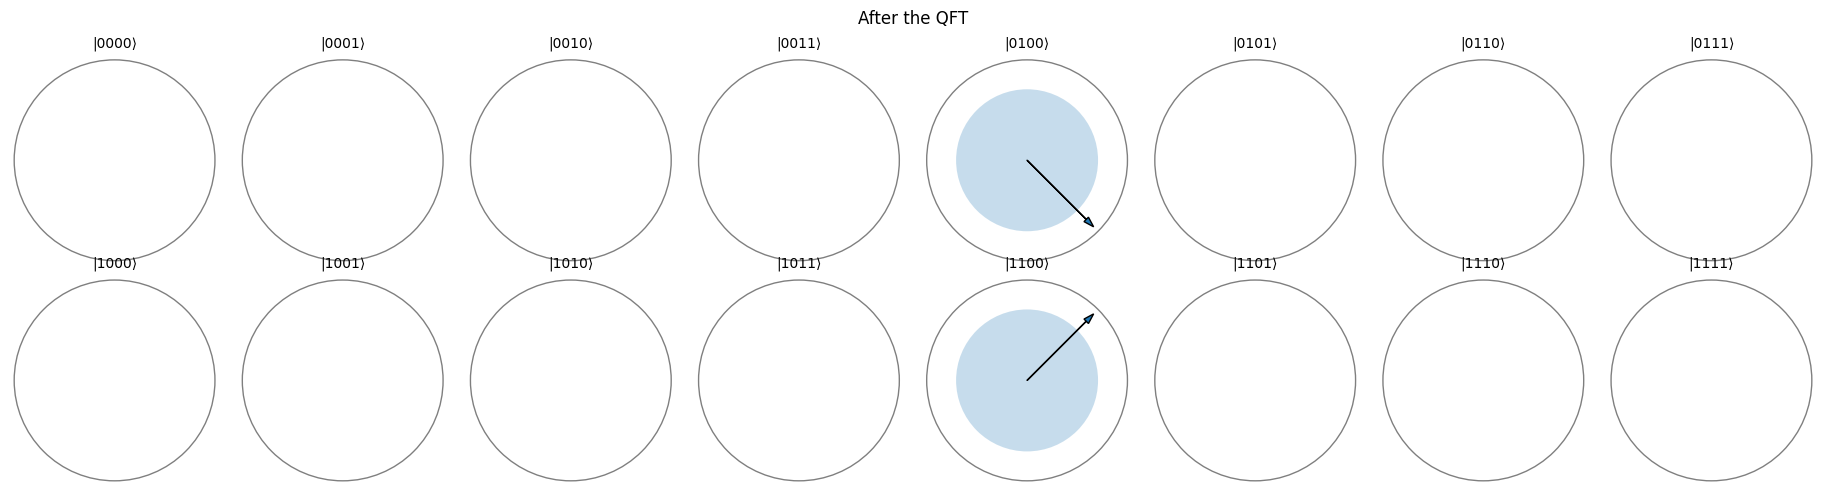

|0100> = | 4>   probability = 0.500   phase =  -45.0°
|1100> = |12>   probability = 0.500   phase =   45.0°


In [9]:
qc_output = QuantumCircuit(N_QUBITS)
prepare_signal(qc_output)
qft(qc_output)
sv_output = sv_from_circ(qc_output)

QubitSystem(sv_output, label="After the QFT").viz_circle()

for k, amplitude in enumerate(sv_output):
    if abs(amplitude) > 1e-9:
        print(f"|{k:04b}> = |{k:2d}>   probability = {abs(amplitude)**2:.3f}   "
              f"phase = {np.degrees(np.angle(amplitude)):6.1f}°")

**Result.** After the QFT all the probability is concentrated in only two states, $|4\rangle = |0100\rangle$ and $|12\rangle = |1100\rangle$, with probability $0.5$ each. The other 14 circles are empty.

- The peak at $|4\rangle$ is the **frequency of the signal**: 4 oscillations in 16 samples, the same number we found above by looking at the input.
- The peak at $|12\rangle = |16 - 4\rangle$ is its mirror image (the "negative frequency" $-4$). It appears because our signal is real (a cosine): a cosine is the sum of two rotating complex exponentials, one with frequency $+4$ and one with $-4$, and $-4 \equiv 12 \pmod{16}$. The classical DFT of a real signal has the same symmetry.
- The phases of the two peaks ($-45°$ and $+45°$) come from the $-\pi/4$ shift of the cosine: the QFT keeps the information about where the wave starts in the phases.

If we measured this state we would get 4 or 12, each with 50% probability, and either result tells us the frequency of the signal.

## Task 2.3 - Discussion

Discuss the results briefly and compare the QFT with the traditional DFT and FFT.

### Our Solution

First we check numerically that our QFT really computes the same thing as the classical DFT. We take the 16 input amplitudes, compute their DFT with numpy's FFT, and compare the result with the state after the QFT. We divide by $\sqrt{16} = 4$ because the QFT must keep the state normalised, while numpy's FFT does not normalise.

In [10]:
dft_of_input = np.fft.fft(sv_input) / np.sqrt(16)

print("QFT output == FFT of the input:", np.allclose(sv_output, dft_of_input))
for k, value in enumerate(dft_of_input):
    if abs(value) > 1e-9:
        print(f"FFT[{k}] = {value.real:+.3f} {value.imag:+.3f}i")

QFT output == FFT of the input: True
FFT[4] = +0.500 -0.500i
FFT[12] = +0.500 +0.500i


**Discussion.**

*Same transform.* The check prints `True`: the QFT output is exactly the DFT of the input signal (up to the $1/\sqrt{N}$ normalisation). The QFT is the DFT, but applied to the **amplitudes of a quantum state** instead of to an array of numbers in memory. This is also why we used the negative angles of the figure: with them the QFT uses the same sign convention as the classical DFT, $e^{-2\pi i\,xk/N}$.

*Cost.* For a signal of $N = 2^n$ samples:

| Method | Number of operations | For our $N = 16$ ($n = 4$) |
|---|---|---|
| DFT (matrix × vector) | $O(N^2)$ | $\approx 256$ |
| FFT | $O(N \log_2 N)$ | $\approx 64$ |
| QFT | $O(n^2) = O\big((\log_2 N)^2\big)$ gates | $12$ gates |

The QFT needs exponentially fewer operations than the FFT: for $n = 30$ qubits ($N \approx 10^9$ samples) it would need only about 500 gates.

*But it is not a faster FFT.* There are two important catches:
1. **We cannot read the result.** The spectrum is stored in the amplitudes, and a measurement returns only *one* basis state, with probability $|\text{amplitude}|^2$. The phases (like the $\pm 45°$ we found) are lost, and to estimate all 16 probabilities we would have to repeat the whole circuit many times. Getting the full spectrum out would cancel the speed-up.
2. **Loading the input.** Here preparing the signal was cheap (4 H gates and one phase gate) because the signal has a very simple structure. Loading $N$ arbitrary numbers into the amplitudes needs, in general, a number of gates that grows with $N$.

So the QFT is not used to replace the FFT in signal processing. It is useful as a **building block inside quantum algorithms** (like phase estimation and Shor's algorithm), where the interesting information is a period or a frequency, and a few measurements are enough to find it. This is exactly what happened here: a single measurement (4 or 12) already reveals the frequency of our signal.

# Bonus Exercise - Discrete Quantum Walk on a Line

In this bonus exercise, you will implement and investigate the Discrete Quantum Walk (DQW) algorithm using Qiskit or Cirq or another quantum computing software of your choice.

A quantum walk is the quantum analog of a classical random walk, but with underlying quantum effects, such as interference. It can be used in various quantum algorithms, such as quantum search and quantum speedup for graph traversal. By the end of the bonus exercise, you will understand how to represent and manipulate quantum states for discrete walks, leveraging quantum arithmetics primitives (albeit in a controlled way) and how quantum superposition and interference work in this context.

A nice introduction to the quantum walk and implementation in Cirq is provided at https://quantumai.google/cirq/experiments/quantum_walks

### Background

A Discrete Quantum Walk on a line consists of two quantum systems:

1. **Position space:** This keeps track of the walker's position on a discrete grid, which can be encoded using qubits. For instance, an **N-qubit system** can encode the position of a walker on one of the $2^N$ lattice points, ranging from $|0\rangle$ to $|2^{N}-1\rangle$.
2. **Coin space** determines whether the walk moves left or right. It can be represented by a **single qubit**, where $|0\rangle$ represents a step to the left and $|1\rangle$ represents a step to the right.

For a graph/lattice of size N = 8, for example, N = 3 qubits are required to encode each node and an extra qubit for the coin.

Each step in the walk is composed of two operations:

1. **Coin Flip:** This applies a Hadamard gate (or a custom coin operator) to the coin qubit, placing it in superposition.
2. **Conditional Increment/Decrement Operators:** Based on the value of the coin qubit, the position qubits are shifted left or right (decrement/increment) on the lattice.

Assume we have the following logic:

* If the coin qubit is $|1\rangle$, move to the right (increase position).
* If the coin qubit is $|0\rangle$, move to the left (decrease position).

However, we might build the shift operator with a controlled-NOT gate, which increments only when the control qubit is $|1\rangle$. If the coin qubit is $|0\rangle$, we apply a NOT gate to flip it to $|1\rangle$, and then apply the shift. After the shift, the NOT gate is applied again to restore the coin qubit to its original state. This technique helps implement the shift correctly for both $|0\rangle$ and $|1\rangle$ states of the coin qubit without changing the basic logic of the controlled operations. Note that NOT gates on the coin qubit are necessary to control the direction of the shift in the position register based on the coin's value. They are part of the controlled operations that conditionally apply shifts left or right and ensure that the quantum walk behaves as expected.

Indicatively, a simple step can be performed as follows, where $\uparrow$ and $\downarrow$ are a controlled version of increment and decrement operators.

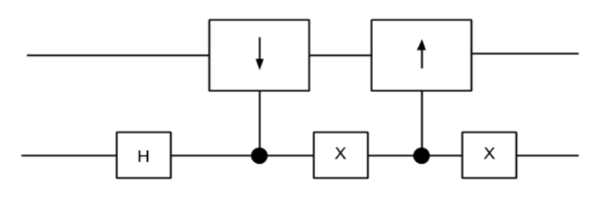

## Task B.1 - Quantum Walk Implementation

Implement a discrete quantum walk over 128 positions using seven position qubits and one coin qubit. Plot the circuit for ten iterations and compare it with Task 1.

### Our Solution

**Registers.** 7 position qubits `pos` ($q_0 \ldots q_6$, positions $0$ to $127$) and one coin qubit `coin`. The walker starts at position $64 = |1000000\rangle$, in the middle of the line: in 30 steps it can move at most 30 places, so it stays between 34 and 94 and never reaches the edges (where it would wrap around, as we saw with overflow in Task 1.2).

**One step of the walk** (as in the figure above):
1. **Coin flip:** a Hadamard on the coin puts it in superposition.
2. **Move right:** increment the position, controlled by the coin (only when the coin is $|1\rangle$).
3. **Move left:** X on the coin, decrement the position controlled by the coin, X again. The X gates make the decrement act when the coin was $|0\rangle$, and then restore the coin.

We follow the rule written in the text (coin $|1\rangle$ → right, coin $|0\rangle$ → left); the figure shows the same structure.

**Controlled increment/decrement and comparison with Task 1.** The shift is the increment of Task 1, with two differences:
- **7 bits instead of 3.** The rule is the same (a bit flips if all the bits below it are 1; start from the top bit), so instead of `CCX, CX, X` we now have a ladder of 7 gates: multi-controlled X gates (`MCX`) with 7, 6, …, 2 controls and a final `CX`.
- **One extra control: the coin.** Every gate gets the coin as an additional control, so the whole increment happens only for coin $|1\rangle$. This is why the `X` on $q_0$ of Task 1 becomes a `CX` here, the `CX` becomes a `CCX`, and so on.

As in Task 1, the decrement is the same gates in reverse order. Since the coin is in superposition, the walker moves left **and** right at the same time.

One step of the walk:


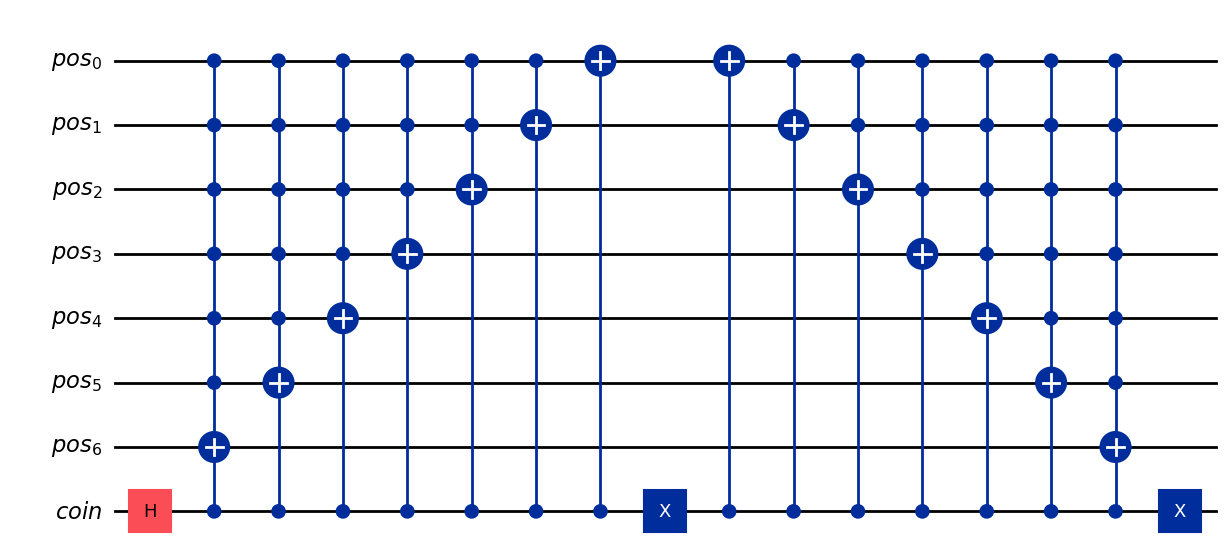

Quantum walk with 10 iterations:


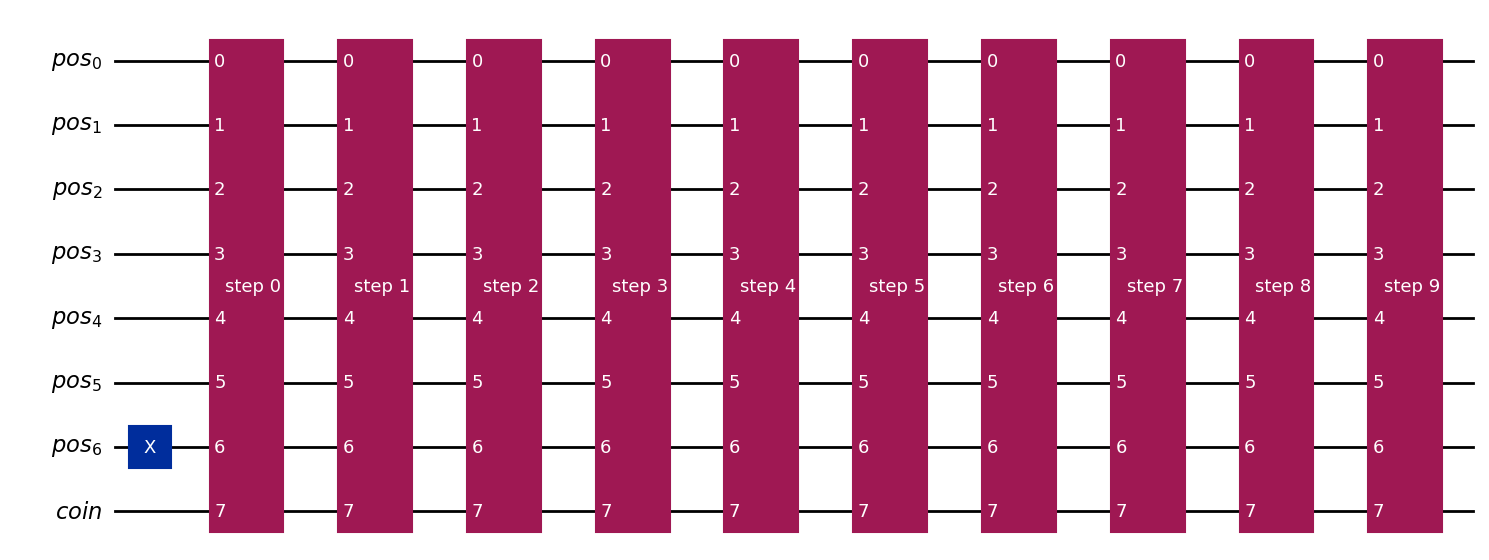

Gates in the full 10-step circuit: {'mcx': 100, 'x': 21, 'ccx': 20, 'cx': 20, 'h': 10} -> total 171


In [18]:
N_POS = 7    # 7 position qubits -> 2^7 = 128 positions
START = 64   # start in the middle of the line: |1000000>


def controlled_increment(qc, coin, pos):
    """+1 on the position register, only if the coin is |1>."""
    for i in reversed(range(1, len(pos))):
        qc.mcx([coin] + pos[:i], pos[i])
    qc.cx(coin, pos[0])


def controlled_decrement(qc, coin, pos):
    """-1 on the position register, only if the coin is |1>: the increment gates in reverse order."""
    qc.cx(coin, pos[0])
    for i in range(1, len(pos)):
        qc.mcx([coin] + pos[:i], pos[i])


def hadamard_coin(qc, coin):
    qc.h(coin)


def walk_step(qc, coin, pos, coin_gate=hadamard_coin):
    """One step: flip the coin, then move right (coin |1>) or left (coin |0>)."""
    coin_gate(qc, coin)
    controlled_increment(qc, coin, pos)  # coin |1> -> move right
    qc.x(coin)
    controlled_decrement(qc, coin, pos)  # coin |0> -> move left
    qc.x(coin)


def start_at_64(qc, pos, coin):
    qc.x(pos[6])  # position |1000000> = 64, coin in |0>


def build_walk(steps, coin_gate=hadamard_coin, prepare=start_at_64):
    """Circuit of a quantum walk with the given number of steps."""
    pos = QuantumRegister(N_POS, "pos")
    coin = QuantumRegister(1, "coin")
    qc = QuantumCircuit(pos, coin)
    prepare(qc, pos, coin[0])
    for _ in range(steps):
        walk_step(qc, coin[0], list(pos), coin_gate)
    return qc


# One step, with all its gates
pos = QuantumRegister(N_POS, "pos")
coin = QuantumRegister(1, "coin")
one_step = QuantumCircuit(pos, coin)
walk_step(one_step, coin[0], list(pos))
print("One step of the walk:")
display(one_step.draw("mpl"))

# Ten iterations: each box is the step drawn above
walk_10 = QuantumCircuit(pos, coin)
start_at_64(walk_10, pos, coin[0])
for _ in range(10):
    step_gate = one_step.to_gate(label=f"step {_}")
    walk_10.append(step_gate, list(pos) + list(coin))
print("Quantum walk with 10 iterations:")
display(walk_10.draw("mpl", fold=-1))

walk_full = build_walk(10)
print("Gates in the full 10-step circuit:", dict(walk_full.count_ops()), "-> total", walk_full.size())

**Result.** In the drawing of one step we can see the coin flip (H), the ladder of the controlled increment (the MCX gates get smaller from the top bit down to $q_0$), and the ladder of the controlled decrement (same gates, opposite order) between the two X gates on the coin. One step has $1 + 7 + 7 + 2 = 17$ gates, so the 10-step walk has $10 \cdot 17 + 1 = 171$ gates (the $+1$ is the X that places the walker at 64), as the printed count shows. In the second drawing each `step` box is exactly the circuit of the first drawing.

Compared to Task 1, the shift operator is much bigger (7 gates with up to 8 qubits each, instead of 3 gates on 3 qubits), but the logic is the same: it is still the reversible "+1" and "−1" from Task 1, only extended to 7 bits and controlled by the coin.

## Task B.2 - Measurement Distribution

Plot the simulated distributions after 10, 20, and 30 iterations. Compare them with a classical random walk and discuss symmetry, spreading speed, and interference.

### Our Solution

For each number of steps we simulate the circuit and compute the exact probability of finding the walker in each position (this is what we would measure with infinitely many shots; the coin qubit is not measured).

For the **classical random walk** with a fair coin, after $t$ steps the walker has made $r$ steps to the right and $t-r$ to the left with probability $\binom{t}{r}/2^t$ (binomial distribution), so it is at position $64 + r - (t - r)$.

To compare the walks with numbers, we also compute:
- the **mean shift**: the average position minus 64 (it tells if the walk drifts to one side);
- the **typical distance** from the start: $\sqrt{\text{average of } (x - 64)^2}$ (it tells how far the walker spreads). For the classical walk it is exactly $\sqrt{t}$.

Note: every step moves the walker by exactly one place, so after $t$ steps it can only be on positions with the same parity as $64 + t$ (both classically and quantum). In the plots we only show these positions, the others always have probability 0.

steps | quantum shift quantum distance | classical shift classical distance
   10 |         -2.45             5.47 |            0.00               3.16
   20 |         -5.59            10.84 |            0.00               4.47
   30 |         -8.36            16.25 |            0.00               5.48


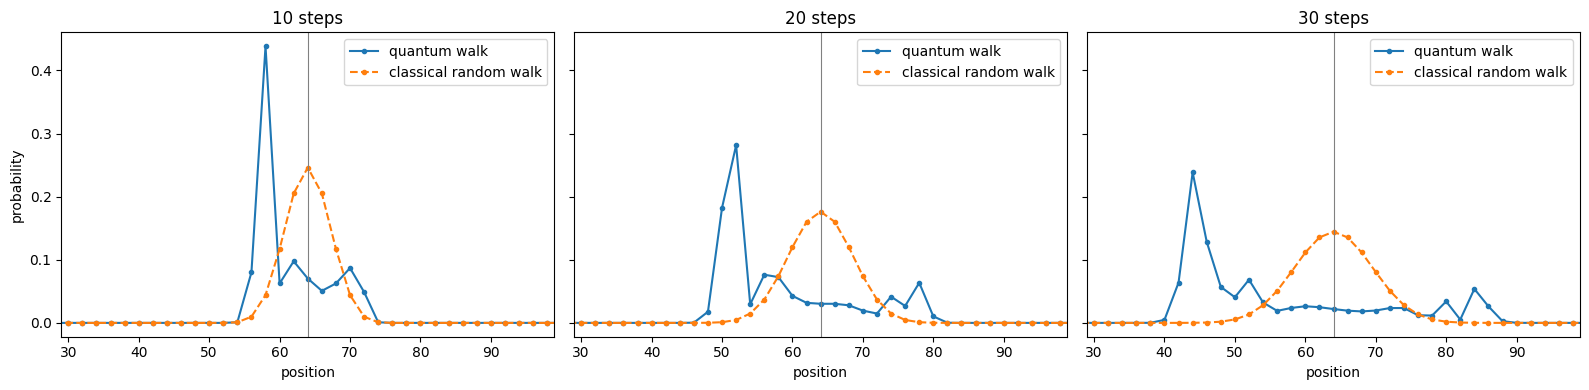

In [12]:
positions = np.arange(2 ** N_POS)


def position_distribution(qc):
    """Exact probability of measuring each position 0..127 (the coin qubit is not measured)."""
    return Statevector(qc).probabilities(qargs=list(range(N_POS)))


def classical_distribution(steps, start=START):
    """Classical random walk with a fair coin: binomial distribution."""
    probs = np.zeros(2 ** N_POS)
    for n_right in range(steps + 1):
        probs[start - steps + 2 * n_right] = math.comb(steps, n_right) / 2 ** steps
    return probs


def shift_and_distance(probs):
    """Mean shift from the start, and typical (root mean square) distance from the start."""
    displacement = positions - START
    mean_shift = np.sum(displacement * probs)
    distance = np.sqrt(np.sum(displacement ** 2 * probs))
    return mean_shift, distance


def plot_distribution(ax, probs, steps, label, **style):
    """Plot only the positions the walker can reach (same parity as START + steps)."""
    x = np.arange((START + steps) % 2, 2 ** N_POS, 2)
    ax.plot(x, probs[x], marker="o", markersize=3, label=label, **style)


fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
print(f"{'steps':>5} | {'quantum shift':>13} {'quantum distance':>16} | {'classical shift':>15} {'classical distance':>18}")
for ax, steps in zip(axes, [10, 20, 30]):
    quantum = position_distribution(build_walk(steps))
    classical = classical_distribution(steps)

    plot_distribution(ax, quantum, steps, "quantum walk")
    plot_distribution(ax, classical, steps, "classical random walk", linestyle="--")
    ax.axvline(START, color="gray", linewidth=0.8)
    ax.set_xlim(START - 35, START + 35)
    ax.set_title(f"{steps} steps")
    ax.set_xlabel("position")
    ax.legend()

    q_shift, q_dist = shift_and_distance(quantum)
    c_shift, c_dist = shift_and_distance(classical)
    print(f"{steps:5d} | {q_shift:13.2f} {q_dist:16.2f} | {c_shift:15.2f} {c_dist:18.2f}")

axes[0].set_ylabel("probability")
plt.tight_layout()
plt.show()

The quantum walk above is **not symmetric**: it drifts to the left (negative mean shift). The reason is that the Hadamard coin does not treat $|0\rangle$ and $|1\rangle$ in the same way: $H|0\rangle = (|0\rangle + |1\rangle)/\sqrt 2$ but $H|1\rangle = (|0\rangle - |1\rangle)/\sqrt 2$. Because of this minus sign, the amplitudes that arrive on one side partly cancel, while those on the other side add up. Which side wins depends on the initial coin: with $|0\rangle$ (our case) the walk drifts left, and starting with the coin in $|1\rangle$ gives the mirror image.

To check this explanation, we start the coin in $(|0\rangle + i|1\rangle)/\sqrt{2}$ (H and then S on the coin). This is an equal mix of "left" and "right", and the factor $i$ makes the two parts never interfere with each other, so the result should be the average of the left-drifting and the right-drifting walk, which is symmetric.

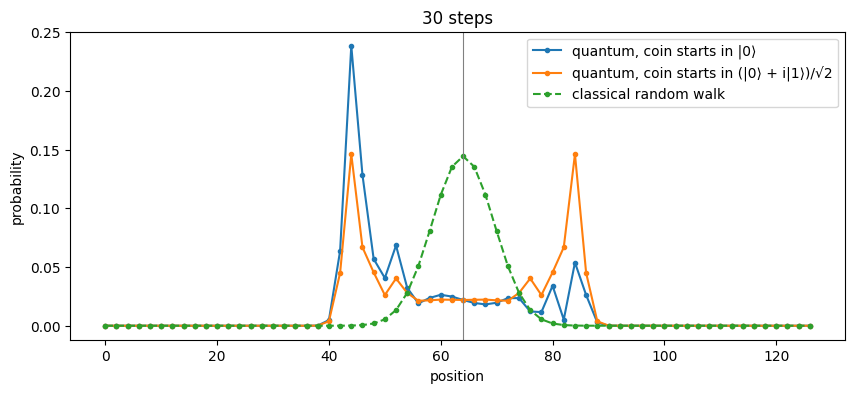

In [13]:
def start_at_64_balanced_coin(qc, pos, coin):
    qc.x(pos[6])  # position 64
    qc.h(coin)    # coin -> (|0> + |1>)/sqrt(2)
    qc.s(coin)    # coin -> (|0> + i|1>)/sqrt(2)


steps = 30
fig, ax = plt.subplots(figsize=(10, 4))
plot_distribution(ax, position_distribution(build_walk(steps)), steps,
                  "quantum, coin starts in |0⟩")
plot_distribution(ax, position_distribution(build_walk(steps, prepare=start_at_64_balanced_coin)), steps,
                  "quantum, coin starts in (|0⟩ + i|1⟩)/√2")
plot_distribution(ax, classical_distribution(steps), steps, "classical random walk", linestyle="--")
ax.axvline(START, color="gray", linewidth=0.8)
ax.set_title(f"{steps} steps")
ax.set_xlabel("position")
ax.set_ylabel("probability")
ax.legend()
plt.show()

**Discussion.**

- **Shape and interference.** The classical walk gives the usual bell-shaped (binomial) curve, centred at the start: most random paths go back and forth and end near the middle. The quantum walk looks completely different: the probability is *low* in the middle and there are large peaks far from the start. The reason is interference. Classically we add the *probabilities* of all the paths; in the quantum walk we add their *amplitudes*, which can also be negative. The many paths that end near the middle have amplitudes with different signs that largely cancel (destructive interference), while near the edges they add up (constructive interference). The small oscillations in the quantum curve are also caused by interference.
- **Symmetry.** The classical walk is symmetric. The Hadamard walk with the coin starting in $|0\rangle$ is not (see above), but with the coin in $(|0\rangle + i|1\rangle)/\sqrt2$ the quantum walk also becomes symmetric, with two equal peaks.
- **Spreading speed.** In the table, the typical distance of the classical walker grows like $\sqrt{t}$ ($3.2 \to 4.5 \to 5.5$), while the quantum one grows linearly with $t$: it roughly doubles from 10 to 20 steps and triples from 10 to 30. So the quantum walker spreads **quadratically faster**: after $t$ steps its typical distance is proportional to $t$ instead of $\sqrt t$. This faster spreading is what makes quantum walks useful for search algorithms on graphs.

## Task B.3 - Initial Condition in Superposition

Initialize the walker in a superposition of two positions, plot the distribution after 30 iterations, and compare it with the earlier distributions.

### Our Solution

We start the walker in an equal superposition of positions $64$ and $80$:

$$\tfrac{1}{\sqrt 2}\big(|64\rangle + |80\rangle\big) = \tfrac{1}{\sqrt 2}\big(|1000000\rangle + |1010000\rangle\big)$$

We prepare it with an X on `pos[6]` (value 64) and a Hadamard on `pos[4]` (which adds 0 or 16). Everything else is the same as in B.2 (Hadamard coin, coin starting in $|0\rangle$, 30 steps), so any difference comes only from the initial condition. The two positions are an even distance apart, so the two parts of the walker land on the same positions and can interfere.

We compare it with:
- the single walker starting at 64 (from B.2);
- a **classical mixture**: the walker starts at 64 *or* at 80, with 50% probability each. Its distribution is just the average of two separate quantum walks, with no interference between them.

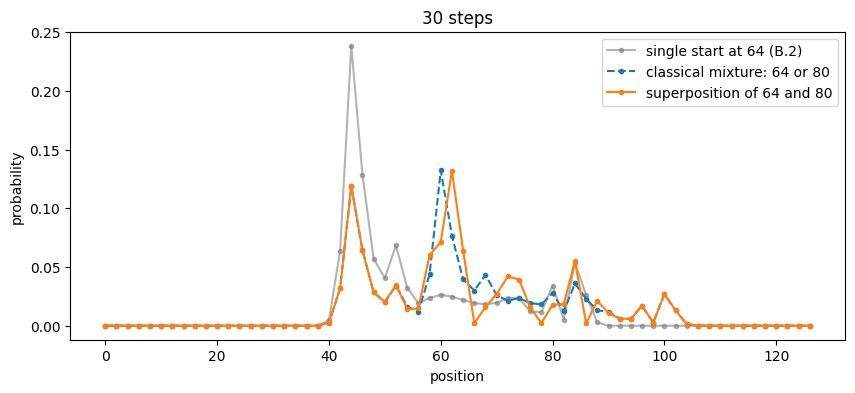

Largest difference between superposition and mixture: 0.061


In [14]:
def start_at_64_and_80(qc, pos, coin):
    qc.x(pos[6])  # position 64
    qc.h(pos[4])  # superposition of 64 and 64 + 16 = 80


def start_at_80(qc, pos, coin):
    qc.x(pos[6])
    qc.x(pos[4])  # position 80


steps = 30
superposition = position_distribution(build_walk(steps, prepare=start_at_64_and_80))
single_64 = position_distribution(build_walk(steps))
single_80 = position_distribution(build_walk(steps, prepare=start_at_80))
mixture = (single_64 + single_80) / 2

fig, ax = plt.subplots(figsize=(10, 4))
plot_distribution(ax, single_64, steps, "single start at 64 (B.2)", color="gray", alpha=0.6)
plot_distribution(ax, mixture, steps, "classical mixture: 64 or 80", linestyle="--")
plot_distribution(ax, superposition, steps, "superposition of 64 and 80")
ax.set_title(f"{steps} steps")
ax.set_xlabel("position")
ax.set_ylabel("probability")
ax.legend()
plt.show()

print("Largest difference between superposition and mixture:", round(float(np.max(np.abs(superposition - mixture))), 3))

**Discussion.**

- Where only one of the two walkers can arrive (left of 50 and right of 94), the superposition and the classical mixture are identical: there is nothing to interfere with.
- In the region reached by both walkers (about 50 to 94), the superposition is clearly different from the mixture: in some positions the probability is higher, in others lower. This is interference between the two starting positions: the amplitudes coming from 64 and from 80 are added *before* squaring, so they can reinforce or cancel each other. In the classical mixture the walker really is in one place or the other, so only the probabilities are added.
- Compared to the single walker of B.2, the distribution is wider (it covers both ranges), and because of this interference it is not simply two shifted copies of the B.2 curve.

So a superposition of two positions is not the same as "not knowing" where the walker started: the relative phase between the two starting positions matters. For example, starting from $(|64\rangle - |80\rangle)/\sqrt2$ would flip the sign of the interference term, so the positions that are enhanced now would be suppressed, and vice versa.

## Task B.4 - ROTY and Biased Quantum Walk

Replace the coin operator with ROTY. Discuss how it changes the probability distribution and how it can produce a biased quantum walk.

### Our Solution

We replace the Hadamard coin with a rotation $R_Y(\theta)$ on the coin:

$$R_Y(\theta) = \begin{pmatrix} \cos(\theta/2) & -\sin(\theta/2) \\ \sin(\theta/2) & \cos(\theta/2) \end{pmatrix}$$

Reading the matrix column by column: a coin in $|0\rangle$ (moving left) stays $|0\rangle$ with amplitude $\cos(\theta/2)$ and turns into $|1\rangle$ with amplitude $\sin(\theta/2)$, and the same holds for $|1\rangle$ (up to a sign). So the angle $\theta$ decides how likely the walker is to **keep its direction** (probability $\cos^2(\theta/2)$) or to **turn around** (probability $\sin^2(\theta/2)$) at each step:
- $\theta = \pi/2$: 50/50, a fair coin, very similar to the Hadamard;
- $\theta < \pi/2$: the walker tends to keep going in the same direction;
- $\theta > \pi/2$: the walker tends to turn around at every step.

We simulate 30 steps (starting at 64 with the coin in $|0\rangle$, as before) for $\theta = \pi/4, \pi/2, 3\pi/4$.

      coin | mean shift | typical distance
   θ = π/4 |     -18.29 |            23.58
   θ = π/2 |      -8.36 |            16.25
  θ = 3π/4 |      -1.79 |             8.31


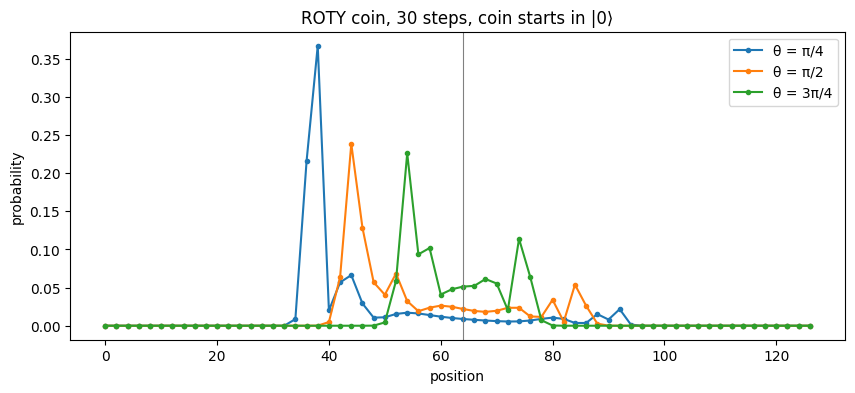

In [15]:
def ry_coin(theta):
    """Coin operator ROTY(theta), used instead of the Hadamard."""
    def coin_gate(qc, coin):
        qc.ry(theta, coin)
    return coin_gate


steps = 30
thetas = {"θ = π/4": np.pi / 4, "θ = π/2": np.pi / 2, "θ = 3π/4": 3 * np.pi / 4}

fig, ax = plt.subplots(figsize=(10, 4))
print(f"{'coin':>10} | {'mean shift':>10} | {'typical distance':>16}")
for name, theta in thetas.items():
    probs = position_distribution(build_walk(steps, coin_gate=ry_coin(theta)))
    plot_distribution(ax, probs, steps, name)
    shift, distance = shift_and_distance(probs)
    print(f"{name:>10} | {shift:10.2f} | {distance:16.2f}")
ax.axvline(START, color="gray", linewidth=0.8)
ax.set_title(f"ROTY coin, {steps} steps, coin starts in |0⟩")
ax.set_xlabel("position")
ax.set_ylabel("probability")
ax.legend()
plt.show()

The direction of the bias is decided by the initial state of the coin. To show it, we repeat the $\theta = \pi/4$ walk with the coin starting in $|1\rangle$ (moving right) instead of $|0\rangle$.

coin starts in |0⟩: mean shift = -18.29
coin starts in |1⟩: mean shift = 18.29


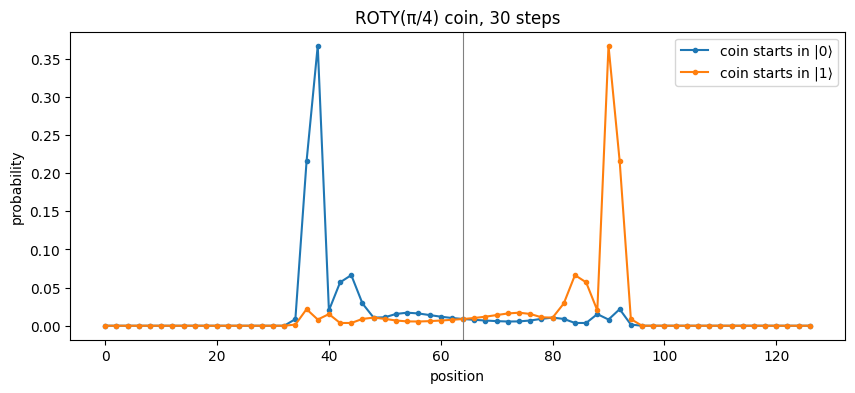

In [16]:
def start_at_64_coin_one(qc, pos, coin):
    qc.x(pos[6])  # position 64
    qc.x(coin)    # coin in |1> (moving right)


theta = np.pi / 4
fig, ax = plt.subplots(figsize=(10, 4))
for name, prepare in [("coin starts in |0⟩", start_at_64), ("coin starts in |1⟩", start_at_64_coin_one)]:
    probs = position_distribution(build_walk(steps, coin_gate=ry_coin(theta), prepare=prepare))
    plot_distribution(ax, probs, steps, name)
    shift, _ = shift_and_distance(probs)
    print(f"{name}: mean shift = {shift:.2f}")
ax.axvline(START, color="gray", linewidth=0.8)
ax.set_title(f"ROTY(π/4) coin, {steps} steps")
ax.set_xlabel("position")
ax.set_ylabel("probability")
ax.legend()
plt.show()

**Discussion.**

- **θ changes how fast the walker spreads.** With $\theta = \pi/4$ the walker rarely turns around, so it keeps moving and reaches the farthest positions (largest typical distance). With $\theta = 3\pi/4$ it turns around at almost every step, zig-zags back and forth and stays close to the start (smallest typical distance). $\theta = \pi/2$ is in between and looks like the Hadamard walk of B.2. In all cases the distance still grows linearly with the number of steps, so the walk spreads faster than the classical one.
- **θ also changes the bias.** With the coin starting in $|0\rangle$ the walker drifts to the left, and the smaller $\theta$ is, the stronger the drift (see the mean shift in the table): a coin that rarely turns keeps most of the amplitude moving in the initial direction. With $\theta = 3\pi/4$ the drift is small and the distribution is almost symmetric.
- **Biased quantum walk.** Combining the two ingredients, the angle $\theta$ (how strong the bias is) and the initial coin state (in which direction), we get a biased walk: with $\theta = \pi/4$ and the coin in $|0\rangle$ most of the probability moves to the left, while with the coin in $|1\rangle$ we get exactly the mirror image, moving to the right (the mean shift only changes sign). In the extreme case $\theta = 0$ the coin never turns and the walker simply moves in one direction at every step.

# Bonus Exercise - Grover's Algorithm

Complete this bonus in the separate notebook supplied with the assignment.

### Our Solution

We completed this bonus directly in the separate notebook [`groover/grovers_algorithm_qiskit.ipynb`](groover/grovers_algorithm_qiskit.ipynb): all the code cells are filled in and all the questions (B1.1, B2.1, B3.1, B3.2 and B3.3) are answered there.

## AI Assistance Disclosure

### Tools and models used

### Per-task usage

### Prompts or interaction summary

### Validation